# Final LAI Error Analysis

This notebook analyzes the saved clean test-set predictions for Random Forest, ResNet-18, and EfficientNet-B0. It does not retrain, tune, or load model checkpoints. All metrics, plots, and observations are computed from the existing prediction CSV files and the clean test metadata.

The clean test split contains 51 images. The Random Forest remains the current LAI candidate when judged by the existing clean test metrics; this notebook describes its error behavior without changing that conclusion.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def find_project_root():
    current = Path.cwd().resolve()
    for candidate in [current, current.parent, *current.parents]:
        if (candidate / 'results' / 'lai_rf_clean_metrics.json').exists():
            return candidate
    raise FileNotFoundError('Could not locate the pixels-to-water project root.')

project_root = find_project_root()
results_dir = project_root / 'results'
data_dir = project_root / 'data'
print(f'Project root: {project_root}')
print(f'Results directory: {results_dir}')

Project root: C:\Users\nihar\OneDrive\Desktop\Water To Pixels\pixels-to-water
Results directory: C:\Users\nihar\OneDrive\Desktop\Water To Pixels\pixels-to-water\results


## Load and align saved predictions

The Random Forest file stores the image identifier in `image`; the CNN files store `image_path`. The alignment key normalizes both formats to `Indoor/<filename>` or `Outdoor/<filename>` and checks that all three models cover the same 51 clean test images.

In [2]:
metric_files = {
    'Random Forest': 'lai_rf_clean_metrics.json',
    'ResNet-18': 'lai_resnet18_clean_metrics.json',
    'EfficientNet-B0': 'lai_efficientnet_b0_clean_metrics.json',
}
prediction_files = {
    'Random Forest': 'lai_rf_clean_predictions.csv',
    'ResNet-18': 'lai_resnet18_clean_predictions.csv',
    'EfficientNet-B0': 'lai_efficientnet_b0_clean_predictions.csv',
}

metrics = {name: json.loads((results_dir / filename).read_text(encoding='utf-8')) for name, filename in metric_files.items()}
test_metadata = pd.read_csv(data_dir / 'lai_test_clean.csv')
test_metadata['alignment_key'] = test_metadata['image_path'].map(lambda value: '/'.join(Path(str(value)).parts[-2:]))

def prediction_alignment_key(value, model_name):
    path = Path(str(value))
    if model_name == 'Random Forest':
        prefix = 'Indoor/' if path.stem.upper().startswith('IN_') else 'Outdoor/'
        filename = path.name[3 if prefix == 'Indoor/' else 4:]
        return prefix + filename
    return '/'.join(path.parts[-2:])

prediction_frames = {}
for model_name, filename in prediction_files.items():
    frame = pd.read_csv(results_dir / filename).rename(columns={'image': 'image_path'})
    required = {'image_path', 'actual_LAI', 'predicted_LAI'}
    if not required.issubset(frame.columns):
        raise ValueError(f'{model_name} is missing columns: {sorted(required - set(frame.columns))}')
    frame['alignment_key'] = frame['image_path'].map(lambda value: prediction_alignment_key(value, model_name))
    frame = frame.merge(test_metadata[['alignment_key', 'environment', 'GrowthStage']], on='alignment_key', how='inner', validate='one_to_one')
    if len(frame) != 51:
        raise AssertionError(f'{model_name}: expected 51 aligned predictions, found {len(frame)}')
    frame['error'] = frame['predicted_LAI'] - frame['actual_LAI']
    prediction_frames[model_name] = frame

common_keys = set.intersection(*(set(frame['alignment_key']) for frame in prediction_frames.values()))
if len(common_keys) != 51:
    raise AssertionError(f'Expected 51 shared clean test images, found {len(common_keys)}')
actual_arrays = [frame['actual_LAI'].to_numpy() for frame in prediction_frames.values()]
if not all(np.allclose(actual_arrays[0], values) for values in actual_arrays[1:]):
    raise AssertionError('Actual LAI values differ across aligned prediction files.')
print(f'Aligned clean test images: {len(common_keys)}')
print('Available subgroup metadata: environment and GrowthStage')

Aligned clean test images: 51
Available subgroup metadata: environment and GrowthStage


In [3]:
def summarize_frame(frame):
    error = frame['error'].to_numpy(dtype=float)
    return {
        'MAE': float(np.mean(np.abs(error))),
        'RMSE': float(np.sqrt(np.mean(error ** 2))),
        'R2': float(r2_score(frame['actual_LAI'], frame['predicted_LAI'])),
        'Bias (predicted - actual)': float(np.mean(error)),
        'Error SD': float(np.std(error, ddof=1)),
        'Overpredictions': int((error > 0).sum()),
        'Underpredictions': int((error < 0).sum()),
    }

overall_table = pd.DataFrame({model: summarize_frame(frame) for model, frame in prediction_frames.items()}).T
overall_table.index.name = 'Model'
overall_table.to_csv(results_dir / 'lai_error_analysis_overall.csv')
display(overall_table.style.format({'MAE': '{:.9f}', 'RMSE': '{:.9f}', 'R2': '{:.6f}', 'Bias (predicted - actual)': '{:.9f}', 'Error SD': '{:.9f}'}))

,MAE,RMSE,R2,Bias (predicted - actual),Error SD,Overpredictions,Underpredictions
Model,,,,,,,
Random Forest,0.006192920,0.009753515,0.865565,0.003529709,0.009182900,35.000000,16.000000
ResNet-18,0.096753566,0.120569790,-19.543175,-0.039741542,0.114964507,20.000000,31.000000
EfficientNet-B0,0.074103718,0.087935380,-9.927425,-0.002105238,0.088784926,26.000000,25.000000


## Actual versus predicted LAI and residual distributions

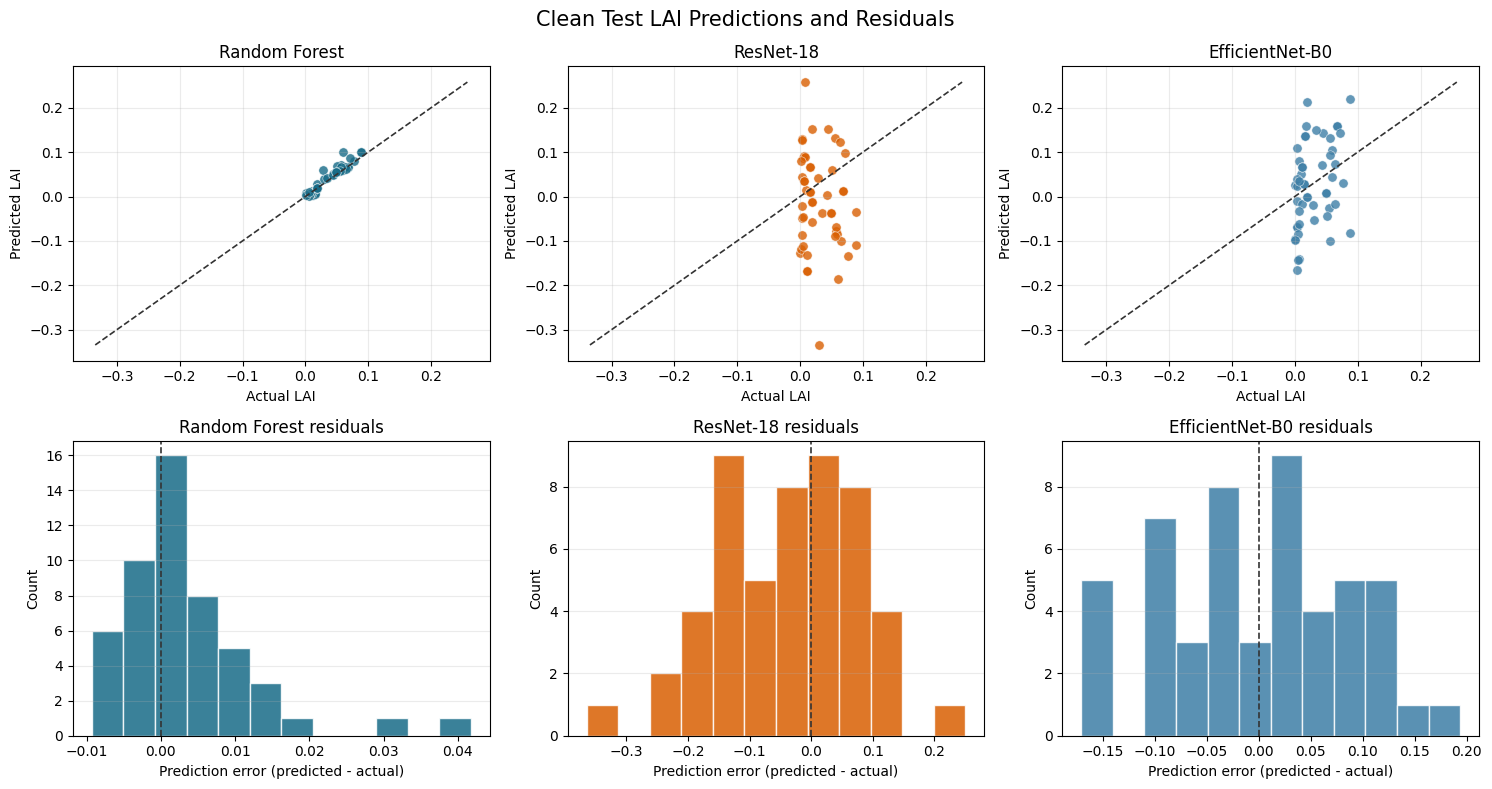

In [4]:
colors = {'Random Forest': '#176b87', 'ResNet-18': '#d95f02', 'EfficientNet-B0': '#3d7ea6'}
all_values = np.concatenate([np.concatenate([frame['actual_LAI'].to_numpy(), frame['predicted_LAI'].to_numpy()]) for frame in prediction_frames.values()])
axis_min = min(0.0, float(all_values.min()))
axis_max = float(all_values.max())
padding = max((axis_max - axis_min) * 0.06, 0.01)

figure, axes = plt.subplots(2, 3, figsize=(15, 8))
for column, (model_name, frame) in enumerate(prediction_frames.items()):
    actual = frame['actual_LAI']
    predicted = frame['predicted_LAI']
    axes[0, column].scatter(actual, predicted, color=colors[model_name], alpha=0.8, edgecolor='white', linewidth=0.4, s=45)
    axes[0, column].plot([axis_min, axis_max], [axis_min, axis_max], '--', color='#333333', linewidth=1.2)
    axes[0, column].set_title(model_name)
    axes[0, column].set_xlabel('Actual LAI')
    axes[0, column].set_ylabel('Predicted LAI')
    axes[0, column].set_xlim(axis_min - padding, axis_max + padding)
    axes[0, column].set_ylim(axis_min - padding, axis_max + padding)
    axes[0, column].grid(alpha=0.25)
    axes[1, column].hist(frame['error'], bins=12, color=colors[model_name], alpha=0.85, edgecolor='white')
    axes[1, column].axvline(0, color='#333333', linestyle='--', linewidth=1.2)
    axes[1, column].set_title(f'{model_name} residuals')
    axes[1, column].set_xlabel('Prediction error (predicted - actual)')
    axes[1, column].set_ylabel('Count')
    axes[1, column].grid(axis='y', alpha=0.25)
figure.suptitle('Clean Test LAI Predictions and Residuals', fontsize=15)
figure.tight_layout()
figure.savefig(results_dir / 'lai_error_analysis.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(figure)

## Error behavior across LAI ranges

Ranges are fixed before calculation so the comparison is reproducible: `<0.01`, `0.01-0.03`, `0.03-0.06`, and `>0.06`.

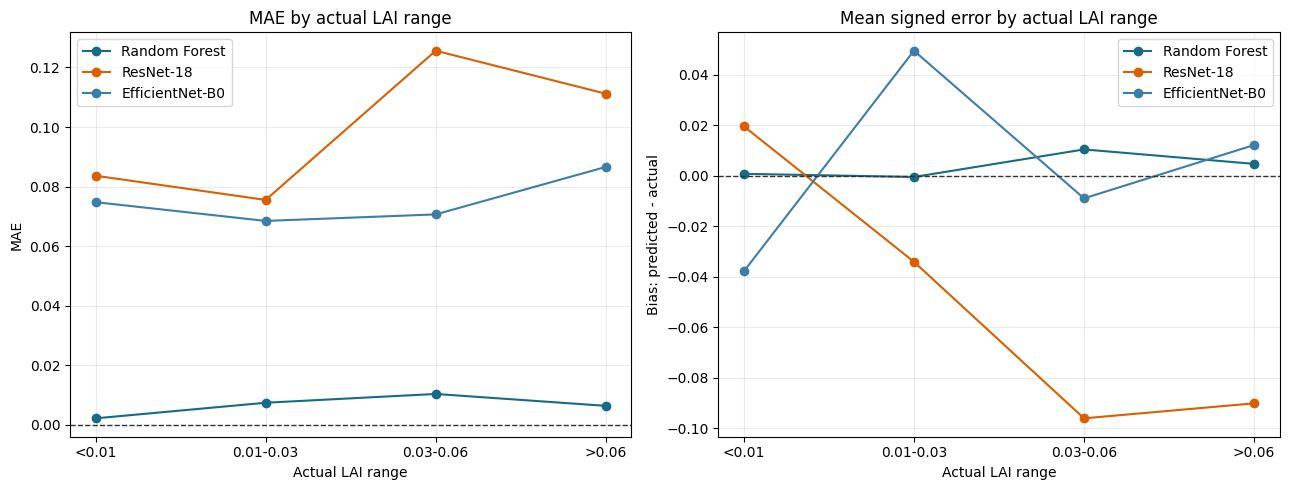

,Model,LAI_range,n,MAE,RMSE,Bias
0,Random Forest,<0.01,18.000000,0.002217658,0.002650645,0.000745342
1,Random Forest,0.01-0.03,12.000000,0.007452290,0.011016912,-0.000506379
2,Random Forest,0.03-0.06,13.000000,0.010401987,0.014571684,0.010401987
3,Random Forest,>0.06,8.000000,0.006408474,0.007971883,0.004681217
4,ResNet-18,<0.01,18.000000,0.083657005,0.100408844,0.019560047
5,ResNet-18,0.01-0.03,12.000000,0.075519968,0.098789144,-0.034088304
6,ResNet-18,0.03-0.06,13.000000,0.125610904,0.153708879,-0.096064990
7,ResNet-18,>0.06,8.000000,0.111178049,0.130221419,-0.090124368
8,EfficientNet-B0,<0.01,18.000000,0.074780173,0.087388831,-0.037870605
9,EfficientNet-B0,0.01-0.03,12.000000,0.068479005,0.089308279,0.049481703


In [5]:
range_bins = [-np.inf, 0.01, 0.03, 0.06, np.inf]
range_labels = ['<0.01', '0.01-0.03', '0.03-0.06', '>0.06']
range_tables = []
for model_name, frame in prediction_frames.items():
    grouped = frame.assign(LAI_range=pd.cut(frame['actual_LAI'], bins=range_bins, labels=range_labels, right=False)).groupby('LAI_range', observed=False)
    table = grouped.apply(lambda group: pd.Series({
        'n': len(group),
        'MAE': np.mean(np.abs(group['error'])),
        'RMSE': np.sqrt(np.mean(group['error'] ** 2)),
        'Bias': np.mean(group['error']),
    }), include_groups=False).reset_index()
    table.insert(0, 'Model', model_name)
    range_tables.append(table)
range_table = pd.concat(range_tables, ignore_index=True)
range_table.to_csv(results_dir / 'lai_error_by_range.csv', index=False)

figure, axes = plt.subplots(1, 2, figsize=(13, 5))
for model_name in prediction_frames:
    subset = range_table[range_table['Model'] == model_name]
    axes[0].plot(subset['LAI_range'], subset['MAE'], marker='o', label=model_name, color=colors[model_name])
    axes[1].plot(subset['LAI_range'], subset['Bias'], marker='o', label=model_name, color=colors[model_name])
axes[0].set_title('MAE by actual LAI range')
axes[0].set_ylabel('MAE')
axes[1].set_title('Mean signed error by actual LAI range')
axes[1].set_ylabel('Bias: predicted - actual')
for axis in axes:
    axis.set_xlabel('Actual LAI range')
    axis.axhline(0, color='#333333', linestyle='--', linewidth=1)
    axis.grid(alpha=0.25)
    axis.legend()
figure.tight_layout()
figure.savefig(results_dir / 'lai_error_by_range.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(figure)
display(range_table.style.format({'MAE': '{:.9f}', 'RMSE': '{:.9f}', 'Bias': '{:.9f}'}))

## Performance by environment and growth stage

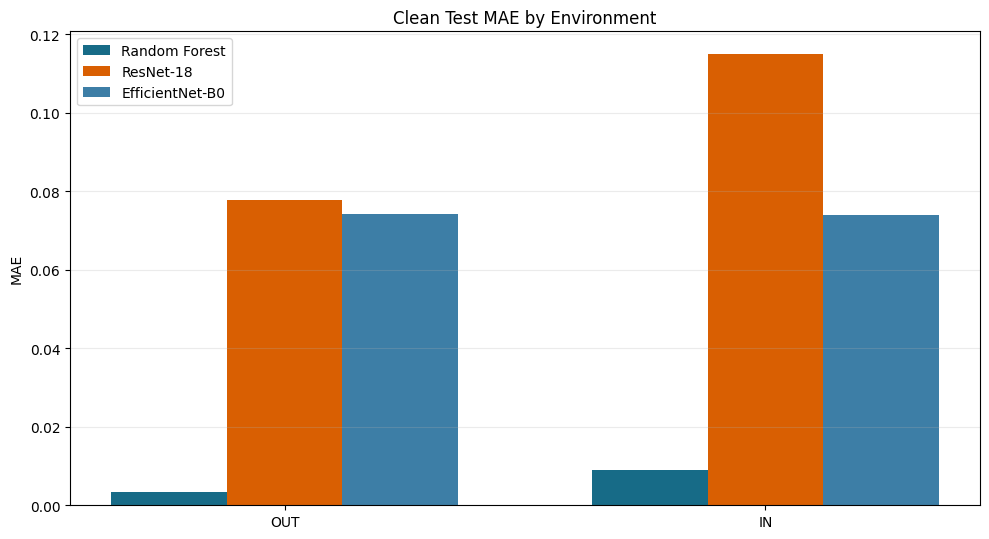

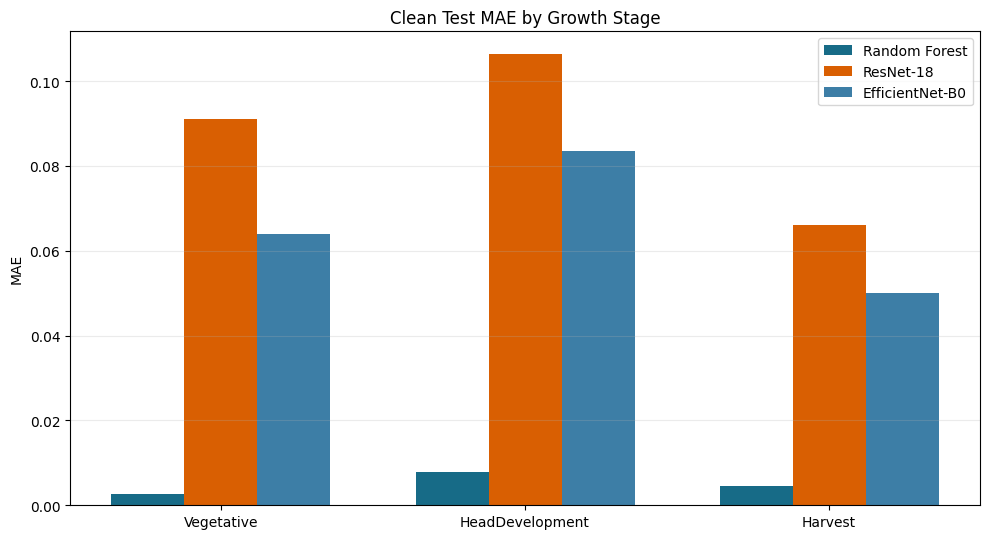

,Model,environment,n,MAE,RMSE,Bias
0,Random Forest,OUT,25.000000,0.003298867,0.004354831,-0.001429947
1,Random Forest,IN,26.000000,0.008975665,0.012975673,0.008298610
2,ResNet-18,OUT,25.000000,0.077752427,0.098912095,0.015311003
3,ResNet-18,IN,26.000000,0.115023891,0.138230677,-0.092676681
4,EfficientNet-B0,OUT,25.000000,0.074154347,0.087555042,-0.010016023
5,EfficientNet-B0,IN,26.000000,0.074055036,0.088299545,0.005501287


,Model,GrowthStage,n,MAE,RMSE,Bias
0,Random Forest,Vegetative,11.000000,0.002709518,0.003608698,0.001761067
1,Random Forest,HeadDevelopment,32.000000,0.007780540,0.011800528,0.005419086
2,Random Forest,Harvest,8.000000,0.004632119,0.005616444,-0.001595911
3,ResNet-18,Vegetative,11.000000,0.091036669,0.098299921,-0.040195548
4,ResNet-18,HeadDevelopment,32.000000,0.106404496,0.134631862,-0.036151196
5,ResNet-18,Harvest,8.000000,0.066010575,0.082972541,-0.053478666
6,EfficientNet-B0,Vegetative,11.000000,0.064045193,0.081848153,0.018590551
7,EfficientNet-B0,HeadDevelopment,32.000000,0.083595864,0.095313356,-0.014645649
8,EfficientNet-B0,Harvest,8.000000,0.049965605,0.061202038,0.019599698


In [6]:
def grouped_error_table(group_column):
    tables = []
    for model_name, frame in prediction_frames.items():
        grouped = frame.groupby(group_column, sort=False)
        table = grouped.apply(lambda group: pd.Series({
            'n': len(group),
            'MAE': np.mean(np.abs(group['error'])),
            'RMSE': np.sqrt(np.mean(group['error'] ** 2)),
            'Bias': np.mean(group['error']),
        }), include_groups=False).reset_index()
        table.insert(0, 'Model', model_name)
        tables.append(table)
    return pd.concat(tables, ignore_index=True)

environment_table = grouped_error_table('environment')
growth_stage_table = grouped_error_table('GrowthStage')
environment_table.to_csv(results_dir / 'lai_error_by_environment.csv', index=False)
growth_stage_table.to_csv(results_dir / 'lai_error_by_growth_stage.csv', index=False)

def plot_grouped_metric(table, group_column, output_name, title):
    groups = list(table[group_column].drop_duplicates())
    x = np.arange(len(groups))
    width = 0.24
    figure, axis = plt.subplots(figsize=(10, 5.5))
    for offset, model_name in enumerate(prediction_frames):
        subset = table[table['Model'] == model_name].set_index(group_column).reindex(groups)
        axis.bar(x + (offset - 1) * width, subset['MAE'], width, label=model_name, color=colors[model_name])
    axis.set_xticks(x)
    axis.set_xticklabels(groups)
    axis.set_ylabel('MAE')
    axis.set_title(title)
    axis.grid(axis='y', alpha=0.25)
    axis.legend()
    figure.tight_layout()
    figure.savefig(results_dir / output_name, dpi=220, bbox_inches='tight')
    plt.show()
    plt.close(figure)

plot_grouped_metric(environment_table, 'environment', 'lai_error_by_environment.png', 'Clean Test MAE by Environment')
plot_grouped_metric(growth_stage_table, 'GrowthStage', 'lai_error_by_growth_stage.png', 'Clean Test MAE by Growth Stage')
display(environment_table.style.format({'MAE': '{:.9f}', 'RMSE': '{:.9f}', 'Bias': '{:.9f}'}))
display(growth_stage_table.style.format({'MAE': '{:.9f}', 'RMSE': '{:.9f}', 'Bias': '{:.9f}'}))

## Concise observations

The statements below are generated from the tables above. They describe the saved clean test predictions only; they are not evidence from retraining or model tuning.

In [7]:
best_model = overall_table['MAE'].idxmin()
worst_model = overall_table['MAE'].idxmax()
largest_range_error = range_table.loc[range_table['MAE'].idxmax()]
largest_environment_error = environment_table.loc[environment_table['MAE'].idxmax()]
largest_stage_error = growth_stage_table.loc[growth_stage_table['MAE'].idxmax()]

print(f'Current LAI candidate: {best_model}, with the lowest clean-test MAE and RMSE among the three models.')
print(f'Worst overall MAE: {worst_model}.')
for model_name, row in overall_table.iterrows():
    direction = 'overpredicts' if row['Bias (predicted - actual)'] > 0 else 'underpredicts'
    print(f'{model_name}: {direction} on average; bias={row["Bias (predicted - actual)"]:.6f}.')
print(f'Largest model/range MAE: {largest_range_error["Model"]} at actual LAI range {largest_range_error["LAI_range"]}.')
print(f'Largest environment MAE: {largest_environment_error["Model"]} on {largest_environment_error["environment"]}.')
print(f'Largest growth-stage MAE: {largest_stage_error["Model"]} during {largest_stage_error["GrowthStage"]}.')
print('Environment and GrowthStage metadata were available for all 51 clean test rows.')
print('Saved figures: lai_error_analysis.png, lai_error_by_range.png, lai_error_by_environment.png, lai_error_by_growth_stage.png')

Current LAI candidate: Random Forest, with the lowest clean-test MAE and RMSE among the three models.
Worst overall MAE: ResNet-18.
Random Forest: overpredicts on average; bias=0.003530.
ResNet-18: underpredicts on average; bias=-0.039742.
EfficientNet-B0: underpredicts on average; bias=-0.002105.
Largest model/range MAE: ResNet-18 at actual LAI range 0.03-0.06.
Largest environment MAE: ResNet-18 on IN.
Largest growth-stage MAE: ResNet-18 during HeadDevelopment.
Environment and GrowthStage metadata were available for all 51 clean test rows.
Saved figures: lai_error_analysis.png, lai_error_by_range.png, lai_error_by_environment.png, lai_error_by_growth_stage.png
